In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


ROOT_DIR = Path("ctg_full_2005_2025")

DATA_FILE = (
    ROOT_DIR
    / "preprocessing"
    / "eligibility_features.csv"
)

OUTPUT_DIR = (
    ROOT_DIR
    / "analysis"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


if not DATA_FILE.exists():
    raise RuntimeError(
        f"Final preprocessing dataset not found: {DATA_FILE}"
    )


df = pd.read_csv(
    DATA_FILE,
    encoding="utf-8-sig",
    low_memory=False,
)


print(f"Rows: {len(df):,}")
print(f"Columns: {len(df.columns)}")
print(f"Unique NCT IDs: {df['nct_id'].nunique():,}")

Rows: 197,671
Columns: 60
Unique NCT IDs: 197,671


In [2]:
EXPECTED_START_YEAR_MIN = 2005
EXPECTED_START_YEAR_MAX = 2025


DOMAIN_COLUMNS = {
    "Neoplasms": "domain_neoplasms",
    "Nervous System Diseases": "domain_nervous_system_diseases",
    "Cardiovascular Diseases": "domain_cardiovascular_diseases",
    "Metabolic Diseases": "domain_metabolic_diseases",
    "Respiratory Tract Diseases": "domain_respiratory_tract_diseases",
    "Infections": "domain_infections",
}


if df["nct_id"].isna().any():
    raise RuntimeError(
        "Missing NCT IDs found in the analysis dataset."
    )

if df["nct_id"].duplicated().any():
    raise RuntimeError(
        "Duplicate NCT IDs found in the analysis dataset."
    )

if df["nct_id"].nunique() != len(df):
    raise RuntimeError(
        "Unique NCT-ID count does not match the number "
        "of analysis records."
    )


study_year = pd.to_numeric(
    df["study_start_year"],
    errors="coerce",
)

if study_year.isna().any():
    raise RuntimeError(
        "Missing or invalid Study Start Year values found."
    )

out_of_range_year = (
    (study_year < EXPECTED_START_YEAR_MIN)
    | (study_year > EXPECTED_START_YEAR_MAX)
)

if out_of_range_year.any():
    raise RuntimeError(
        "Study Start Year values outside the expected "
        f"{EXPECTED_START_YEAR_MIN}–"
        f"{EXPECTED_START_YEAR_MAX} range found."
    )


# Every study must belong to at least one selected disease domain.
if df["n_disease_domains"].isna().any():
    raise RuntimeError(
        "Missing n_disease_domains values found."
    )

if (
    df["n_disease_domains"] < 1
).any():
    raise RuntimeError(
        "Analysis dataset contains studies with no "
        "selected disease-domain membership."
    )


# Only single-domain and multiple-domain studies should remain.
valid_classification_statuses = {
    "single_domain",
    "multiple_domains",
}

if not df[
    "disease_classification_status"
].isin(valid_classification_statuses).all():
    raise RuntimeError(
        "Unexpected disease-classification status found "
        "in the analysis dataset."
    )


# Boolean domain indicators must reconcile with n_disease_domains.
domain_indicator_columns = list(
    DOMAIN_COLUMNS.values()
)

indicator_domain_count = (
    df[domain_indicator_columns]
    .sum(axis=1)
)

if not (
    indicator_domain_count
    == df["n_disease_domains"]
).all():
    raise RuntimeError(
        "Disease-domain indicators do not reconcile with "
        "n_disease_domains."
    )


# All six prespecified disease domains must be represented.
unrepresented_domains = [
    domain
    for domain, column in DOMAIN_COLUMNS.items()
    if not df[column].any()
]

if unrepresented_domains:
    raise RuntimeError(
        "One or more prespecified disease domains are not "
        f"represented: {unrepresented_domains}"
    )


print("Analysis input integrity checks passed.")
print(f"Studies: {len(df):,}")
print(
    f"Study Start Year range: "
    f"{int(study_year.min())}–{int(study_year.max())}"
)
print(
    f"Disease domains represented: "
    f"{len(DOMAIN_COLUMNS)}"
)
print(
    "Studies with single-domain membership: "
    f"{int((df['n_disease_domains'] == 1).sum()):,}"
)
print(
    "Studies with multiple-domain membership: "
    f"{int((df['n_disease_domains'] > 1).sum()):,}"
)

Analysis input integrity checks passed.
Studies: 197,671
Study Start Year range: 2005–2025
Disease domains represented: 6
Studies with single-domain membership: 153,677
Studies with multiple-domain membership: 43,994


In [3]:
def summarize_categorical(
    data,
    variable,
):
    """
    Summarize a categorical study characteristic in the full
    analysis cohort.

    Missing values are retained as a separate category.
    Percentages use the full analysis cohort as the denominator.
    """

    summary = (
        data[variable]
        .fillna("MISSING")
        .value_counts(dropna=False)
        .rename_axis("category")
        .reset_index(name="n_studies")
    )

    summary["percent_of_cohort"] = (
        summary["n_studies"]
        / len(data)
        * 100
    )

    return summary

In [4]:
study_status_summary = summarize_categorical(
    df,
    "study_status",
)

phase_summary = summarize_categorical(
    df,
    "phase",
)

sex_summary = summarize_categorical(
    df,
    "sex",
)


for summary_name, summary_df in [
    ("study status", study_status_summary),
    ("phase", phase_summary),
    ("sex", sex_summary),
]:
    if summary_df["n_studies"].sum() != len(df):
        raise RuntimeError(
            f"{summary_name.capitalize()} counts do not "
            "reconcile with the analysis cohort."
        )

In [5]:
study_status_summary.to_csv(
    OUTPUT_DIR / "study_status_summary.csv",
    index=False,
)

phase_summary.to_csv(
    OUTPUT_DIR / "phase_summary.csv",
    index=False,
)

sex_summary.to_csv(
    OUTPUT_DIR / "sex_summary.csv",
    index=False,
)

In [6]:
enrollment_numeric = pd.to_numeric(
    df["enrollment"],
    errors="coerce",
)

enrollment_summary = pd.DataFrame(
    {
        "n_available": [
            int(enrollment_numeric.notna().sum())
        ],
        "n_missing": [
            int(enrollment_numeric.isna().sum())
        ],
        "median": [
            enrollment_numeric.median()
        ],
        "q1": [
            enrollment_numeric.quantile(0.25)
        ],
        "q3": [
            enrollment_numeric.quantile(0.75)
        ],
        "min": [
            enrollment_numeric.min()
        ],
        "max": [
            enrollment_numeric.max()
        ],
    }
)

enrollment_summary.to_csv(
    OUTPUT_DIR / "enrollment_summary.csv",
    index=False,
)

In [7]:
country_scope = np.select(
    [
        df["n_countries"] == 0,
        df["n_countries"] == 1,
        df["n_countries"] > 1,
    ],
    [
        "No country information",
        "Single-country",
        "Multicountry",
    ],
    default="Unknown",
)

country_scope_summary = (
    pd.Series(
        country_scope,
        name="country_scope",
    )
    .value_counts()
    .rename_axis("country_scope")
    .reset_index(name="n_studies")
)

country_scope_summary["percent_of_cohort"] = (
    country_scope_summary["n_studies"]
    / len(df)
    * 100
)

if (
    country_scope_summary["n_studies"].sum()
    != len(df)
):
    raise RuntimeError(
        "Country-scope counts do not reconcile "
        "with the analysis cohort."
    )

country_scope_summary.to_csv(
    OUTPUT_DIR / "country_scope_summary.csv",
    index=False,
)

In [8]:
print("Study status")
print(
    study_status_summary.to_string(
        index=False,
        formatters={
            "percent_of_cohort": "{:.1f}".format,
        },
    )
)

print()
print("Phase")
print(
    phase_summary.to_string(
        index=False,
        formatters={
            "percent_of_cohort": "{:.1f}".format,
        },
    )
)

print()
print("Sex")
print(
    sex_summary.to_string(
        index=False,
        formatters={
            "percent_of_cohort": "{:.1f}".format,
        },
    )
)

print()
print("Enrollment")
print(
    enrollment_summary.to_string(
        index=False,
    )
)

print()
print("Country scope")
print(
    country_scope_summary.to_string(
        index=False,
        formatters={
            "percent_of_cohort": "{:.1f}".format,
        },
    )
)

Study status
               category  n_studies percent_of_cohort
              COMPLETED     107491              54.4
                UNKNOWN      30665              15.5
             RECRUITING      20463              10.4
             TERMINATED      16774               8.5
  ACTIVE_NOT_RECRUITING       9487               4.8
              WITHDRAWN       6975               3.5
     NOT_YET_RECRUITING       3952               2.0
ENROLLING_BY_INVITATION       1121               0.6
              SUSPENDED        743               0.4

Phase
     category  n_studies percent_of_cohort
      MISSING      88611              44.8
       PHASE2      36097              18.3
       PHASE1      21594              10.9
       PHASE3      20087              10.2
       PHASE4      15084               7.6
PHASE1|PHASE2       9639               4.9
PHASE2|PHASE3       3541               1.8
 EARLY_PHASE1       3018               1.5

Sex
category  n_studies percent_of_cohort
     ALL     174148 

In [9]:
# Study membership by disease domain
disease_domain_rows = []

for disease_domain, indicator_column in DOMAIN_COLUMNS.items():

    n_studies = int(
        df[indicator_column].sum()
    )

    disease_domain_rows.append(
        {
            "disease_domain": disease_domain,
            "n_studies": n_studies,
            "percent_of_cohort": (
                n_studies
                / len(df)
                * 100
            ),
        }
    )


studies_by_disease_domain = pd.DataFrame(
    disease_domain_rows
)


if (
    studies_by_disease_domain["n_studies"] <= 0
).any():
    raise RuntimeError(
        "One or more prespecified disease domains "
        "have no study membership."
    )


studies_by_disease_domain.to_csv(
    OUTPUT_DIR / "studies_by_disease_domain.csv",
    index=False,
)


print("Study membership by disease domain")
print(
    studies_by_disease_domain.to_string(
        index=False,
        formatters={
            "percent_of_cohort": "{:.2f}".format,
        },
    )
)

print()
print(
    "Note: disease-domain memberships are not mutually "
    "exclusive; counts and percentages may overlap."
)

Study membership by disease domain
            disease_domain  n_studies percent_of_cohort
                 Neoplasms      70155             35.49
   Nervous System Diseases      49429             25.01
   Cardiovascular Diseases      38373             19.41
        Metabolic Diseases      25360             12.83
Respiratory Tract Diseases      33028             16.71
                Infections      28510             14.42

Note: disease-domain memberships are not mutually exclusive; counts and percentages may overlap.


In [10]:
def summarize_categorical_by_domain(
    data,
    variable,
):
    """
    Summarize a categorical study characteristic within each
    non-mutually-exclusive disease domain.

    Missing values are retained as a separate category.
    Percentages use the number of studies belonging to each
    disease domain as the denominator.
    """

    summary_parts = []

    for disease_domain, indicator_column in DOMAIN_COLUMNS.items():

        domain_data = data.loc[
            data[indicator_column]
        ]

        domain_total = len(domain_data)

        if domain_total == 0:
            raise RuntimeError(
                f"No studies found for disease domain: "
                f"{disease_domain}"
            )

        domain_summary = (
            domain_data[variable]
            .fillna("MISSING")
            .value_counts(dropna=False)
            .rename_axis("category")
            .reset_index(name="n_studies")
        )

        domain_summary.insert(
            0,
            "disease_domain",
            disease_domain,
        )

        domain_summary["domain_total"] = (
            domain_total
        )

        domain_summary["percent_within_domain"] = (
            domain_summary["n_studies"]
            / domain_total
            * 100
        )

        summary_parts.append(
            domain_summary
        )

    summary = pd.concat(
        summary_parts,
        ignore_index=True,
    )

    summary["disease_domain"] = pd.Categorical(
        summary["disease_domain"],
        categories=list(DOMAIN_COLUMNS.keys()),
        ordered=True,
    )

    return (
        summary
        .sort_values(
            [
                "disease_domain",
                "n_studies",
            ],
            ascending=[
                True,
                False,
            ],
        )
        .reset_index(drop=True)
    )


study_status_by_domain = (
    summarize_categorical_by_domain(
        df,
        "study_status",
    )
)

phase_by_domain = (
    summarize_categorical_by_domain(
        df,
        "phase",
    )
)


# Each categorical distribution must reconcile within
# its corresponding disease domain.
for disease_domain, indicator_column in DOMAIN_COLUMNS.items():

    expected_domain_total = int(
        df[indicator_column].sum()
    )

    observed_status_total = int(
        study_status_by_domain.loc[
            study_status_by_domain["disease_domain"]
            == disease_domain,
            "n_studies",
        ].sum()
    )

    observed_phase_total = int(
        phase_by_domain.loc[
            phase_by_domain["disease_domain"]
            == disease_domain,
            "n_studies",
        ].sum()
    )

    if observed_status_total != expected_domain_total:
        raise RuntimeError(
            f"Study-status counts do not reconcile for "
            f"{disease_domain}."
        )

    if observed_phase_total != expected_domain_total:
        raise RuntimeError(
            f"Phase counts do not reconcile for "
            f"{disease_domain}."
        )


study_status_by_domain.to_csv(
    OUTPUT_DIR / "study_status_by_disease_domain.csv",
    index=False,
)

phase_by_domain.to_csv(
    OUTPUT_DIR / "phase_by_disease_domain.csv",
    index=False,
)


print("Study status by disease domain")
print(
    study_status_by_domain.to_string(
        index=False,
        formatters={
            "percent_within_domain": "{:.1f}".format,
        },
    )
)

print()
print("Phase by disease domain")
print(
    phase_by_domain.to_string(
        index=False,
        formatters={
            "percent_within_domain": "{:.1f}".format,
        },
    )
)

Study status by disease domain
            disease_domain                category  n_studies  domain_total percent_within_domain
                 Neoplasms               COMPLETED      30134         70155                  43.0
                 Neoplasms                 UNKNOWN      11327         70155                  16.1
                 Neoplasms              RECRUITING       9871         70155                  14.1
                 Neoplasms              TERMINATED       8177         70155                  11.7
                 Neoplasms   ACTIVE_NOT_RECRUITING       5508         70155                   7.9
                 Neoplasms               WITHDRAWN       2854         70155                   4.1
                 Neoplasms      NOT_YET_RECRUITING       1695         70155                   2.4
                 Neoplasms               SUSPENDED        312         70155                   0.4
                 Neoplasms ENROLLING_BY_INVITATION        277         70155            

In [11]:
sex_by_domain = summarize_categorical_by_domain(
    df,
    "sex",
)


# Sex-category counts must reconcile within each disease domain.
for disease_domain, indicator_column in DOMAIN_COLUMNS.items():

    expected_domain_total = int(
        df[indicator_column].sum()
    )

    observed_sex_total = int(
        sex_by_domain.loc[
            sex_by_domain["disease_domain"]
            == disease_domain,
            "n_studies",
        ].sum()
    )

    if observed_sex_total != expected_domain_total:
        raise RuntimeError(
            f"Sex counts do not reconcile for "
            f"{disease_domain}."
        )


enrollment_numeric = pd.to_numeric(
    df["enrollment"],
    errors="coerce",
)


enrollment_parts = []

for disease_domain, indicator_column in DOMAIN_COLUMNS.items():

    domain_enrollment = enrollment_numeric.loc[
        df[indicator_column]
    ]

    domain_total = int(
        df[indicator_column].sum()
    )

    n_available = int(
        domain_enrollment.notna().sum()
    )

    enrollment_parts.append(
        {
            "disease_domain": disease_domain,
            "n_total": domain_total,
            "n_available": n_available,
            "n_missing": (
                domain_total - n_available
            ),
            "median": domain_enrollment.median(),
            "q1": domain_enrollment.quantile(0.25),
            "q3": domain_enrollment.quantile(0.75),
            "min": domain_enrollment.min(),
            "max": domain_enrollment.max(),
        }
    )


enrollment_by_domain = pd.DataFrame(
    enrollment_parts
)


enrollment_by_domain["disease_domain"] = pd.Categorical(
    enrollment_by_domain["disease_domain"],
    categories=list(DOMAIN_COLUMNS.keys()),
    ordered=True,
)

enrollment_by_domain = (
    enrollment_by_domain
    .sort_values("disease_domain")
    .reset_index(drop=True)
)


sex_by_domain.to_csv(
    OUTPUT_DIR / "sex_by_disease_domain.csv",
    index=False,
)

enrollment_by_domain.to_csv(
    OUTPUT_DIR / "enrollment_by_disease_domain.csv",
    index=False,
)


print("Sex by disease domain")
print(
    sex_by_domain.to_string(
        index=False,
        formatters={
            "percent_within_domain": "{:.1f}".format,
        },
    )
)

print()
print("Enrollment by disease domain")
print(
    enrollment_by_domain.to_string(
        index=False,
    )
)

Sex by disease domain
            disease_domain category  n_studies  domain_total percent_within_domain
                 Neoplasms      ALL      56038         70155                  79.9
                 Neoplasms   FEMALE      10075         70155                  14.4
                 Neoplasms     MALE       4033         70155                   5.7
                 Neoplasms  MISSING          9         70155                   0.0
   Nervous System Diseases      ALL      46461         49429                  94.0
   Nervous System Diseases   FEMALE       1801         49429                   3.6
   Nervous System Diseases     MALE       1145         49429                   2.3
   Nervous System Diseases  MISSING         22         49429                   0.0
   Cardiovascular Diseases      ALL      36779         38373                  95.8
   Cardiovascular Diseases   FEMALE        922         38373                   2.4
   Cardiovascular Diseases     MALE        658         38373     

In [12]:
# Country scope by disease domain

country_scope = np.select(
    [
        df["n_countries"] == 0,
        df["n_countries"] == 1,
        df["n_countries"] > 1,
    ],
    [
        "No country information",
        "Single-country",
        "Multicountry",
    ],
    default="Unknown",
)


country_scope_parts = []

for disease_domain, indicator_column in DOMAIN_COLUMNS.items():

    domain_scope = pd.Series(
        country_scope[df[indicator_column]],
        name="country_scope",
    )

    domain_total = int(
        df[indicator_column].sum()
    )

    domain_summary = (
        domain_scope
        .value_counts()
        .rename_axis("country_scope")
        .reset_index(name="n_studies")
    )

    domain_summary.insert(
        0,
        "disease_domain",
        disease_domain,
    )

    domain_summary["domain_total"] = (
        domain_total
    )

    domain_summary["percent_within_domain"] = (
        domain_summary["n_studies"]
        / domain_total
        * 100
    )

    if (
        domain_summary["n_studies"].sum()
        != domain_total
    ):
        raise RuntimeError(
            f"Country-scope counts do not reconcile for "
            f"{disease_domain}."
        )

    country_scope_parts.append(
        domain_summary
    )


country_scope_by_domain = pd.concat(
    country_scope_parts,
    ignore_index=True,
)


country_scope_by_domain["disease_domain"] = pd.Categorical(
    country_scope_by_domain["disease_domain"],
    categories=list(DOMAIN_COLUMNS.keys()),
    ordered=True,
)


country_scope_by_domain = (
    country_scope_by_domain
    .sort_values(
        [
            "disease_domain",
            "country_scope",
        ]
    )
    .reset_index(drop=True)
)


country_scope_by_domain.to_csv(
    OUTPUT_DIR / "country_scope_by_disease_domain.csv",
    index=False,
)


print("Country scope by disease domain")
print(
    country_scope_by_domain.to_string(
        index=False,
        formatters={
            "percent_within_domain": "{:.1f}".format,
        },
    )
)

Country scope by disease domain
            disease_domain          country_scope  n_studies  domain_total percent_within_domain
                 Neoplasms           Multicountry       8907         70155                  12.7
                 Neoplasms No country information       4277         70155                   6.1
                 Neoplasms         Single-country      56971         70155                  81.2
   Nervous System Diseases           Multicountry       3823         49429                   7.7
   Nervous System Diseases No country information       3457         49429                   7.0
   Nervous System Diseases         Single-country      42149         49429                  85.3
   Cardiovascular Diseases           Multicountry       3889         38373                  10.1
   Cardiovascular Diseases No country information       2677         38373                   7.0
   Cardiovascular Diseases         Single-country      31807         38373                  82.

In [13]:
eligibility_text_measures = [
    "n_total_listed_items",
    "total_eligibility_word_count",
    "mean_sentence_length",
    "flesch_reading_ease",
]


domain_measure_rows = []

for disease_domain, indicator_column in DOMAIN_COLUMNS.items():

    domain_df = df.loc[
        df[indicator_column]
    ]

    for variable in eligibility_text_measures:

        values = pd.to_numeric(
            domain_df[variable],
            errors="coerce",
        )

        domain_measure_rows.append(
            {
                "disease_domain": disease_domain,
                "variable": variable,
                "domain_total": len(domain_df),
                "n_available": int(
                    values.notna().sum()
                ),
                "n_missing": int(
                    values.isna().sum()
                ),
                "median": values.median(),
                "q1": values.quantile(0.25),
                "q3": values.quantile(0.75),
                "min": values.min(),
                "max": values.max(),
            }
        )


domain_measure_summary = pd.DataFrame(
    domain_measure_rows
)


domain_measure_summary["disease_domain"] = pd.Categorical(
    domain_measure_summary["disease_domain"],
    categories=list(DOMAIN_COLUMNS.keys()),
    ordered=True,
)

domain_measure_summary = (
    domain_measure_summary
    .sort_values(
        [
            "disease_domain",
            "variable",
        ]
    )
    .reset_index(drop=True)
)


domain_measure_summary.to_csv(
    OUTPUT_DIR
    / "eligibility_text_measures_by_disease_domain.csv",
    index=False,
)


print("Eligibility-text measures by disease domain")
print(
    domain_measure_summary.to_string(
        index=False,
    )
)

Eligibility-text measures by disease domain
            disease_domain                     variable  domain_total  n_available  n_missing     median         q1         q3         min      max
                 Neoplasms          flesch_reading_ease         70155        70155          0  33.590153  27.407834  40.001083 -148.803443  121.220
                 Neoplasms         mean_sentence_length         70155        70155          0  13.560976   9.750000  17.566667    1.000000  194.500
                 Neoplasms         n_total_listed_items         70155        69359        796  16.000000  10.000000  25.000000    1.000000  147.000
                 Neoplasms total_eligibility_word_count         70155        70155          0 261.000000 113.000000 537.000000    1.000000 2978.000
   Nervous System Diseases          flesch_reading_ease         49429        49429          0  36.565000  28.661665  44.682782 -301.272500  121.220
   Nervous System Diseases         mean_sentence_length         4942

In [14]:
expressions = [
    "quantitative_present",
    "temporal_present",
    "negation_present",
    "conditional_present",
    "exception_present",
]


# Presence indicators must be complete because prevalence uses
# all studies within each disease domain as the denominator.
for variable in expressions:
    if df[variable].isna().any():
        raise RuntimeError(
            f"Missing values found in {variable}."
        )


domain_expressions_prevalence_rows = []

for disease_domain, indicator_column in DOMAIN_COLUMNS.items():

    domain_df = df.loc[
        df[indicator_column]
    ]

    n_domain = len(domain_df)

    if n_domain == 0:
        raise RuntimeError(
            f"No studies found for disease domain: "
            f"{disease_domain}"
        )

    for variable in expressions:

        n_present = int(
            domain_df[variable].sum()
        )

        domain_expressions_prevalence_rows.append(
            {
                "disease_domain": disease_domain,
                "variable": variable,
                "n_studies": n_domain,
                "n_present": n_present,
                "prevalence_percent": (
                    n_present / n_domain * 100
                ),
            }
        )


domain_expressions_prevalence = pd.DataFrame(
    domain_expressions_prevalence_rows
)


domain_expressions_prevalence["disease_domain"] = pd.Categorical(
    domain_expressions_prevalence["disease_domain"],
    categories=list(DOMAIN_COLUMNS.keys()),
    ordered=True,
)

domain_expressions_prevalence = (
    domain_expressions_prevalence
    .sort_values(
        [
            "disease_domain",
            "variable",
        ]
    )
    .reset_index(drop=True)
)


domain_expressions_prevalence.to_csv(
    OUTPUT_DIR
    / "expressions_characteristic_prevalence_by_disease_domain.csv",
    index=False,
)


print(
    "Expression-characteristic prevalence "
    "by disease domain"
)

print(
    domain_expressions_prevalence.to_string(
        index=False,
        formatters={
            "prevalence_percent": "{:.2f}".format,
        },
    )
)

Expression-characteristic prevalence by disease domain
            disease_domain             variable  n_studies  n_present prevalence_percent
                 Neoplasms  conditional_present      70155      27770              39.58
                 Neoplasms    exception_present      70155      34332              48.94
                 Neoplasms     negation_present      70155      53311              75.99
                 Neoplasms quantitative_present      70155      65109              92.81
                 Neoplasms     temporal_present      70155      50188              71.54
   Nervous System Diseases  conditional_present      49429       9486              19.19
   Nervous System Diseases    exception_present      49429      10681              21.61
   Nervous System Diseases     negation_present      49429      27721              56.08
   Nervous System Diseases quantitative_present      49429      43177              87.35
   Nervous System Diseases     temporal_present      49

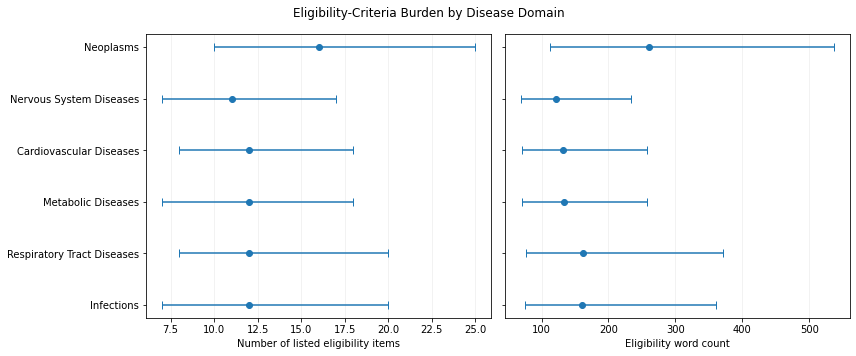

In [15]:
figure1_variables = [
    (
        "n_total_listed_items",
        "Number of listed eligibility items",
    ),
    (
        "total_eligibility_word_count",
        "Eligibility word count",
    ),
]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5),
)


for ax, (variable, label) in zip(
    axes,
    figure1_variables,
):

    plot_df = (
        domain_measure_summary.loc[
            domain_measure_summary["variable"]
            == variable
        ]
        .set_index("disease_domain")
        .reindex(list(DOMAIN_COLUMNS.keys()))
        .reset_index()
    )

    y = np.arange(
        len(plot_df)
    )

    median = plot_df["median"].to_numpy()
    q1 = plot_df["q1"].to_numpy()
    q3 = plot_df["q3"].to_numpy()

    lower_error = median - q1
    upper_error = q3 - median

    ax.errorbar(
        median,
        y,
        xerr=[
            lower_error,
            upper_error,
        ],
        fmt="o",
        capsize=4,
    )

    ax.set_yticks(y)
    ax.set_yticklabels(
        plot_df["disease_domain"]
    )

    ax.invert_yaxis()

    ax.set_xlabel(label)

    ax.grid(
        axis="x",
        alpha=0.2,
    )


axes[1].tick_params(
    axis="y",
    labelleft=False,
)


fig.suptitle(
    "Eligibility-Criteria Burden by Disease Domain",
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "figure_1_eligibility_burden_by_disease_domain.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

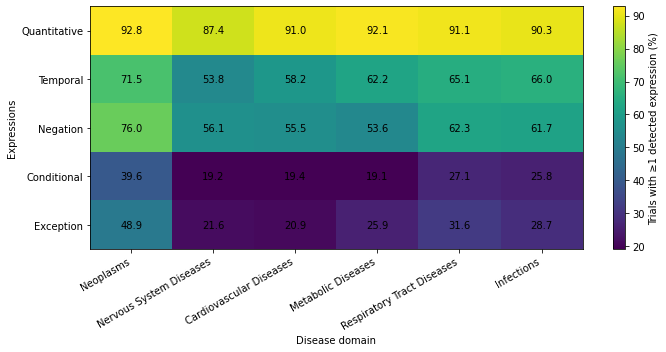

In [16]:
expression_labels = {
    "quantitative_present": "Quantitative",
    "temporal_present": "Temporal",
    "negation_present": "Negation",
    "conditional_present": "Conditional",
    "exception_present": "Exception",
}


prevalence_plot_df = (
    domain_expressions_prevalence
    .pivot(
        index="variable",
        columns="disease_domain",
        values="prevalence_percent",
    )
    .reindex(
        index=list(expression_labels.keys()),
        columns=list(DOMAIN_COLUMNS.keys()),
    )
)


prevalence_plot_df.index = [
    expression_labels[variable]
    for variable in prevalence_plot_df.index
]


fig, ax = plt.subplots(
    figsize=(10, 5),
)


image = ax.imshow(
    prevalence_plot_df.to_numpy(),
    aspect="auto",
)


ax.set_xticks(
    np.arange(
        len(prevalence_plot_df.columns)
    )
)

ax.set_xticklabels(
    prevalence_plot_df.columns,
    rotation=30,
    ha="right",
)


ax.set_yticks(
    np.arange(
        len(prevalence_plot_df.index)
    )
)

ax.set_yticklabels(
    prevalence_plot_df.index
)


for row_index in range(
    prevalence_plot_df.shape[0]
):
    for column_index in range(
        prevalence_plot_df.shape[1]
    ):

        value = prevalence_plot_df.iloc[
            row_index,
            column_index,
        ]

        ax.text(
            column_index,
            row_index,
            f"{value:.1f}",
            ha="center",
            va="center",
        )


colorbar = fig.colorbar(
    image,
    ax=ax,
)

colorbar.set_label(
    "Trials with ≥1 detected expression (%)"
)


ax.set_xlabel(
    "Disease domain"
)

ax.set_ylabel(
    "Expressions"
)


fig.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "figure_2_expression_characteristics_by_disease_domain.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()